# 量子変分回路と量子ニューラルネットワーク

このレッスンでは、データ分類タスクのためにいくつかの変分量子回路、いわゆる変分量子分類器 (VQC) を実装します。かつては、古典的なニューラルネットワークとの類推から、VQC の一部を量子ニューラルネットワーク (QNN) と呼ぶことが一般的でした。実際、畳み込み層のような古典的なニューラルネットワークから借用した構造が VQC で重要な役割を果たす場合もあります。このように類推が強く成り立つ場合には、QNN という呼び方は有用な表現になり得ます。しかし、パラメーター化量子回路は必ずしもニューラルネットワークの一般的な構造に従う必要はありません。たとえば、すべてのデータを最初の (入力) 層で読み込む必要はなく、最初の層で一部のデータを読み込み、いくつかのゲートを適用してから、追加のデータを読み込むこともできます (このプロセスはデータの「再アップロード」と呼ばれます)。したがって、QNN はパラメーター化量子回路の一部であると考えるべきであり、有用な量子回路を探求する際に、古典的なニューラルネットワークとの類推に縛られるべきではありません。

このレッスンで扱うデータセットは、水平または垂直の縞を含む画像で構成されており、未知の画像を線の向きに応じて 2 つのカテゴリーのいずれかにラベル付けすることが目標です。これを VQC で実現します。その過程で、計算を改善し、スケールアップする方法についても取り上げます。ここでのデータセットは、古典的には非常に簡単に分類できるものです。このデータセットは単純さを理由に選ばれており、問題の量子的な部分に集中し、データセットの属性が量子回路のどの部分に対応しうるかを見ることができます。古典アルゴリズムが非常に効率的なこのような単純なケースで、量子による高速化を期待するのは妥当ではありません。

このレッスンを終えると、次のことができるようになります。

* 画像のデータを量子回路に読み込む
* VQC (または QNN) のアンザッツを構築し、問題に合わせて調整する
* VQC/QNN を訓練し、それを使ってテストデータに対して正確な予測を行う
* 問題をスケールアップし、現在の量子コンピューターの限界を認識する



## データの生成

まずデータを構築します。Qiskit patterns のフレームワークでは、データセットを明示的に生成することはあまりありません。しかし、データの種類と準備は、量子コンピューティングを機械学習にうまく適用するうえで非常に重要です。以下のコードは、所定のピクセル寸法を持つ画像のデータセットを定義します。画像の 1 つの行または列全体に値 $\pi/2$ が割り当てられ、残りのピクセルには区間 $(0,\pi/4)$ のランダムな値が割り当てられます。このランダムな値はデータ中のノイズです。コードにざっと目を通し、画像がどのように生成されるかを理解しておいてください。後ほど画像をスケールアップします。



In [1]:
# このコードは分類対象の画像を定義します:

import numpy as np

# 「ピクセル」/量子ビットの総数
size = 8
# 画像の一方の次元 (縦と呼びますが、どちらでも構いません)。`size` の約数である必要があります
vert_size = 2
# 検出する線 (黄色) の長さ。画像の最小の次元以下である必要があります
# (`<=min(vert_size,size/vert_size)`
line_size = 2


def generate_dataset(num_images):
    images = []
    labels = []
    hor_array = np.zeros((size - (line_size - 1) * vert_size, size))
    ver_array = np.zeros((round(size / vert_size) * (vert_size - line_size + 1), size))

    j = 0
    for i in range(0, size - 1):
        if i % (size / vert_size) <= (size / vert_size) - line_size:
            for p in range(0, line_size):
                hor_array[j][i + p] = np.pi / 2
            j += 1

    # 隣接する 2 つの要素を pi/2 にし、次の行へ移ります。このリストをグリッドに折りたたむため、
    # size/vert_size - linesize にある「ピクセル」を避けるよう注意します。

    j = 0
    for i in range(0, round(size / vert_size) * (vert_size - line_size + 1)):
        for p in range(0, line_size):
            ver_array[j][i + p * round(size / vert_size)] = np.pi / 2
        j += 1

    # 長さ/行数の間隔で要素を pi/2 にします。こうすると折りたたんだときに、
    # それらの要素が上下に並びます。

    for n in range(num_images):
        rng = np.random.randint(0, 2)
        if rng == 0:
            labels.append(-1)
            random_image = np.random.randint(0, len(hor_array))
            images.append(np.array(hor_array[random_image]))

        elif rng == 1:
            labels.append(1)
            random_image = np.random.randint(0, len(ver_array))
            images.append(np.array(ver_array[random_image]))
            # 水平または垂直の配列として 0 または 1 をランダムに選び、対応するラベルを
            # 割り当てます。

        # ノイズを生成
        for i in range(size):
            if images[-1][i] == 0:
                images[-1][i] = np.random.rand() * np.pi / 4
    return images, labels


hor_size = round(size / vert_size)

上のコードでは、画像に垂直 (+1) または水平 (-1) の線が含まれているかを示すラベルも生成されていることに注意してください。次に、sklearn を使って 100 枚の画像からなるデータセットを訓練用とテスト用のセットに (対応するラベルとともに) 分割します。ここでは、データセットの $70%$ を訓練に使用し、残りの $30%$ をテスト用に取っておきます。



In [2]:
from sklearn.model_selection import train_test_split

np.random.seed(42)
images, labels = generate_dataset(200)

train_images, test_images, train_labels, test_labels = train_test_split(
    images, labels, test_size=0.3, random_state=246
)

データセットのいくつかの要素をプロットして、これらの線がどのように見えるかを確認しましょう。



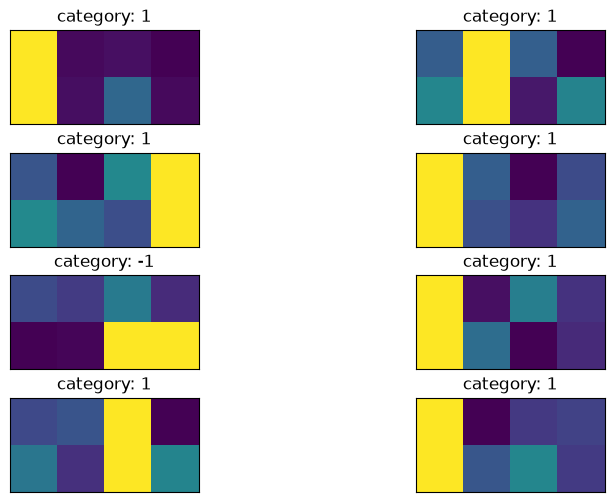

In [3]:
import matplotlib.pyplot as plt

# カテゴリーを識別できるようにサブプロットのタイトルを作成
titles = []
for i in range(8):
    title = "category: " + str(train_labels[i])
    titles.append(title)

# サブプロットを使って画像を並べた図を生成します。
fig, ax = plt.subplots(4, 2, figsize=(10, 6), subplot_kw={"xticks": [], "yticks": []})

for i in range(8):
    ax[i // 2, i % 2].imshow(
        train_images[i].reshape(vert_size, hor_size),
        aspect="equal",
    )
    ax[i // 2, i % 2].set_title(titles[i])
plt.subplots_adjust(wspace=0.1, hspace=0.3)

これらの画像はそれぞれ、`train_labels` 内の単純なリスト形式のラベルと引き続き対になっています。



In [4]:
print(train_labels[:8])

[1, 1, 1, 1, -1, 1, 1, 1]


## 変分量子分類器: 最初の試み

### Qiskit patterns ステップ 1: 問題を量子回路にマッピングする

目標は、データベクトル / 画像 $\vec{x}$ を正しいカテゴリーにマッピングする、パラメーター $\theta$ を持つ関数 $f$ を見つけることです: $f_\theta(\vec{x}) \rightarrow \pm1$。これは、それぞれ異なる目的によって識別できる少数の層からなる VQC を使って実現します。

$$
f_\theta(\vec{x}) = \langle 0|U^{\dagger}(\vec{x})W^\dagger(\theta)OW(\theta)U(\vec{x})|0\rangle
$$

ここで、$U(\vec{x})$ はエンコーディング回路であり、これまでのレッスンで見てきたように多くの選択肢があります。$W(\theta)$ は変分回路ブロック (訓練可能な回路ブロック) であり、$\theta$ は訓練するパラメーターの集合です。これらのパラメーターは古典的な最適化アルゴリズムによって変化させられ、量子回路による画像の分類が最も良くなるパラメーターの集合が探索されます。この変分回路は「アンザッツ」と呼ばれることもあります。最後に、$O$ は Estimator プリミティブを使って推定するオブザーバブルです。層がこの順序で並ぶ必要はなく、完全に分離している必要さえありません。技術的な動機があれば、複数の変分層やエンコーディング層を任意の順序で配置できます。

まず、データをエンコードするための特徴量マップを選びます。ここでは `z_feature_map` を使用します。これは、他のいくつかの特徴量マップと比べて回路の深さを浅く抑えられるためです。



In [5]:
from qiskit.circuit.library import z_feature_map

# データの特徴量 1 つにつき 1 量子ビット
num_qubits = len(train_images[0])

# データのエンコーディング
# Qiskit はパラメーターをアルファベット順に並べることに注意してください。データのエンコーディングが
# 回路の最初の部分 (特徴量マップ) に確実に入るよう、パラメーターの接頭辞として "a" を割り当てます。
feature_map = z_feature_map(num_qubits, parameter_prefix="a")

次に、訓練するアンザッツを決める必要があります。アンザッツを選ぶ際には多くの考慮事項があります。完全な説明はこの入門の範囲を超えるため、ここではいくつかの考慮事項のカテゴリーを挙げるにとどめます。

1. **ハードウェア:** 現代の量子コンピューターはすべて、古典コンピューターと比べてエラーが発生しやすく、ノイズの影響を受けやすいものです。過度に深いアンザッツ (特にトランスパイル後の 2 量子ビットの深さが深いもの) を使っても良い結果は得られません。関連する問題として、量子コンピューターには量子ビットのレイアウトがあり、量子コンピューター上で隣接している物理量子ビットもあれば、互いに非常に離れているものもあります。隣接する量子ビットをエンタングルさせても深さはそれほど増えませんが、非常に離れた量子ビットをエンタングルさせると深さが大幅に増える可能性があります。エンタングルさせるためには、SWAP ゲートを挿入して情報を隣接する量子ビットに移動させる必要があるためです。
2. **問題:** アンザッツの指針となりうる問題に関する情報があれば、それを活用してください。たとえば、このレッスンのデータは水平線と垂直線の画像で構成されています。隣接する色/値の間のどのような相関が、水平線や垂直線の画像を特徴付けるのかを考えることができます。アンザッツのどのような属性が、隣接ピクセル間のこの相関に対応するでしょうか。この点については、このレッスンの後半でより技術的に再検討します。しかし今のところは、隣接するピクセルに対応する量子ビット間にエンタングルメントと CNOT ゲートを含めるのが良さそうだ、とだけ言っておきましょう。より大局的には、その問題が本当に量子回路を使って解くのが最善なのか、それとも同じくらいうまく解ける古典アルゴリズムが存在しうるのかを検討してください。
3. **パラメーターの数:** 回路内の独立にパラメーター化された量子ゲートはそれぞれ、古典的に最適化すべき空間を広げ、その結果として収束が遅くなります。さらに、問題がスケールアップするにつれて、*バレンプラトー* に遭遇することがあります。この用語は、問題のサイズが大きくなるにつれて、変分量子アルゴリズムの最適化ランドスケープが指数関数的に平坦で特徴のないものになる現象を指します。これにより勾配消失が起こり、アルゴリズムを効果的に訓練することが難しくなります[\[1\]](#references)。バレンプラトーは、VQC/QNN のような変分量子アルゴリズムに関係します。なお、バレンプラトーを回避するうえで考慮すべきなのはパラメーター数の増加だけではないことに注意してください。他の考慮事項として、大域的なコスト関数やパラメーターのランダムな初期化などがあります。

このレッスンでは、アンザッツ構築における良い実践の簡単な例をいくつか見ていきます。まずは以下のアンザッツを試してみましょう。後でこれを修正するために戻ってきます。



5
2+ qubit depth: 3


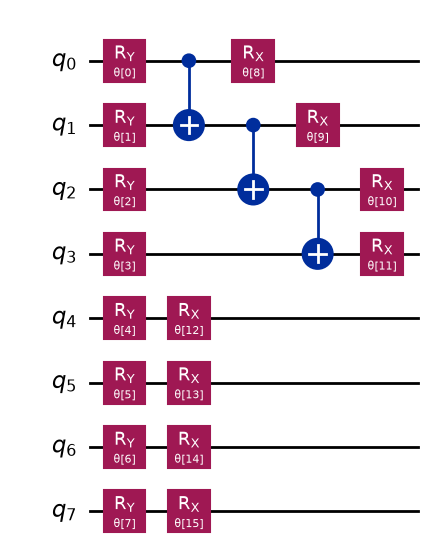

In [6]:
# 必要なパッケージをインポート
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector

# 画像のピクセル数と同じ数の量子ビットで回路を初期化
qnn_circuit = QuantumCircuit(size)

# 各量子ビットに 2 つの変分パラメーターを持たせることにします。
params = ParameterVector("θ", length=2 * size)

# 1 つ目の変分層:
for i in range(size):
    qnn_circuit.ry(params[i], i)

# CNOT ゲートを配置したい量子ビットのペアのリストです。
# これらの選び方はまだ自明ではありません。
qnn_cnot_list = [[0, 1], [1, 2], [2, 3]]

for i in range(len(qnn_cnot_list)):
    qnn_circuit.cx(qnn_cnot_list[i][0], qnn_cnot_list[i][1])

# 2 つ目の変分層:
for i in range(size):
    qnn_circuit.rx(params[size + i], i)

# 回路の深さと 2 量子ビットゲートの深さを確認
print(qnn_circuit.decompose().depth())
print(
    f"2+ qubit depth: {qnn_circuit.decompose().depth(lambda instr: len(instr.qubits) > 1)}"
)

# 回路を描画
qnn_circuit.draw("mpl")

データエンコーディングと変分回路の準備ができたので、これらを組み合わせて完全なアンザッツを作成できます。この場合、量子回路の構成要素はニューラルネットワークの構成要素とよく似ており、$U(\vec{x})$ は画像から入力値を読み込む層に最も近く、$W(\theta)$ は可変の「重み」の層のようなものです。この場合にはこの類推が成り立つため、一部の命名規則で「qnn」を採用していますが、この類推が VQC の探求を制限するものであってはなりません。

![QML\_CR\_background\_QNN\_circuit-2.png](https://quantum.cloud.ibm.com/learning/images/courses/quantum-machine-learning/qvc-qnn/qml-cr-background-qnn-circuit.avif)



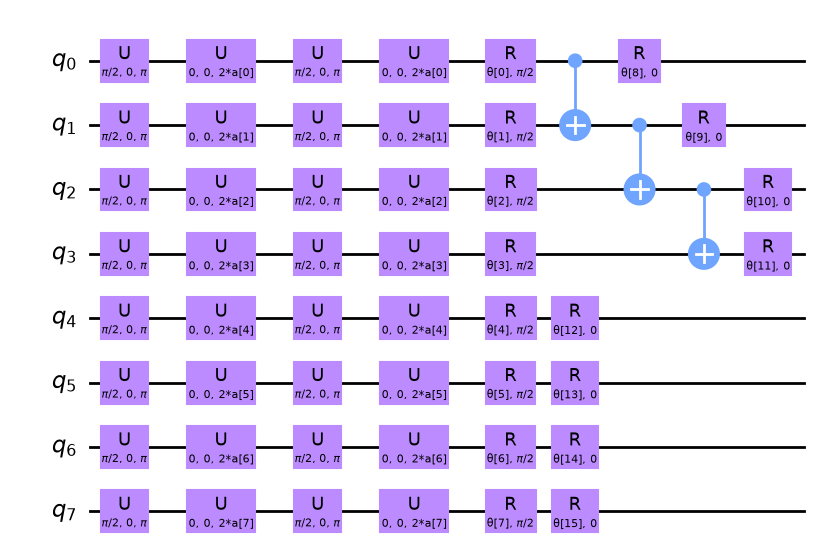

In [7]:
# QNN アンザッツ
ansatz = qnn_circuit

# 特徴量マップとアンザッツを結合
full_circuit = QuantumCircuit(num_qubits)
full_circuit.compose(feature_map, range(num_qubits), inplace=True)
full_circuit.compose(ansatz, range(num_qubits), inplace=True)

# 回路を表示
full_circuit.decompose().draw("mpl", style="clifford", fold=-1)

次に、コスト関数で使用できるようにオブザーバブルを定義する必要があります。このオブザーバブルの期待値は Estimator を使って求めます。問題に基づいた良いアンザッツを選んでいれば、各量子ビットには分類に関係する情報が含まれているはずです。情報をより少ない量子ビットに集約する層 (*畳み込み層* と呼ばれます) を追加して、(畳み込みニューラルネットワークのように) 回路内の一部の量子ビットだけを測定すればよいようにすることもできます。あるいは、各量子ビットから何らかの属性を測定することもできます。ここでは後者を選ぶので、各量子ビットに `Z` 演算子を含めます。$Z$ を選ぶことに特別な理由があるわけではありませんが、十分な動機があります。

* これは二値分類タスクであり、$Z$ の測定では 2 つの結果が得られます。
* $Z$ の固有値 ($\pm 1$) は適度に離れており、Estimator の結果は区間 \[-1, +1] に収まるため、単純に 0 をしきい値として使用できます。
* パウリ Z 基底での測定は、追加のゲートのオーバーヘッドなしに簡単に行えます。

したがって、Z は非常に自然な選択です。



In [8]:
from qiskit.quantum_info import SparsePauliOp

observable = SparsePauliOp.from_list([("Z" * (num_qubits), 1)])

量子回路と、推定したいオブザーバブルが揃いました。次に、この回路を実行して最適化するためにいくつか必要なものがあります。まず、順伝播を実行する関数が必要です。以下の関数は `input_params` と `weight_params` を別々に受け取ることに注意してください。前者は画像のデータを表す静的なパラメーターの集合であり、後者は最適化される可変のパラメーターの集合です。



In [9]:
from qiskit.primitives import BaseEstimatorV2
from qiskit.quantum_info.operators.base_operator import BaseOperator


def forward(
    circuit: QuantumCircuit,
    input_params: np.ndarray,
    weight_params: np.ndarray,
    estimator: BaseEstimatorV2,
    observable: BaseOperator,
) -> np.ndarray:
    """
    ニューラルネットワークの順伝播。

    Args:
        circuit: データ読み込みゲートとニューラルネットワークのアンザッツからなる回路。
        input_params: データエンコーディングのパラメーター。
        weight_params: ニューラルネットワークのアンザッツのパラメーター。
        estimator: EstimatorV2 プリミティブ。
        observable: 期待値を計算する単一のオブザーバブル。

    Returns:
        expectation_values: 期待値の配列 (オブザーバブルが 1 つの場合) または行列 (オブザーバブルが複数の場合)。
        行がオブザーバブル、列がデータサンプルに対応します。
    """
    num_samples = input_params.shape[0]
    weights = np.broadcast_to(weight_params, (num_samples, len(weight_params)))
    params = np.concatenate((input_params, weights), axis=1)
    pub = (circuit, observable, params)
    job = estimator.run([pub])
    result = job.result()[0]
    expectation_values = result.data.evs

    return expectation_values

### 損失関数

次に、ラベルの予測値と計算値の差を計算する損失関数が必要です。この関数は、アルゴリズムが予測したラベルと正しいラベルを受け取り、平均二乗誤差を返します。損失関数にはさまざまな種類があります。ここでは、例として MSE を選びました。



In [10]:
def mse_loss(predict: np.ndarray, target: np.ndarray) -> np.ndarray:
    """
    平均二乗誤差 (MSE)。

    prediction: ニューラルネットワークの順伝播による予測値。
    target: 正解ラベル。

    output: MSE 損失。
    """
    if len(predict.shape) <= 1:
        return ((predict - target) ** 2).mean()
    else:
        raise AssertionError("input should be 1d-array")

古典的な最適化器で使用するために、可変パラメーター (重み) の関数である、少し異なる損失関数も定義しておきましょう。この関数はアンザッツのパラメーターのみを入力として受け取り、順伝播と損失のためのその他の変数はグローバルパラメーターとして設定します。最適化器は、さまざまな重みをサンプリングし、コスト/損失関数の出力を下げようとすることでモデルを訓練します。



In [11]:
def mse_loss_weights(weight_params: np.ndarray) -> np.ndarray:
    """
    最適化器がアンザッツのパラメーターを更新するためのコスト関数。

    weight_params: 最適化器によって更新されるアンザッツのパラメーター。

    output: MSE 損失。
    """
    predictions = forward(
        circuit=circuit,
        input_params=input_params,
        weight_params=weight_params,
        estimator=estimator,
        observable=observable,
    )

    cost = mse_loss(predict=predictions, target=target)
    objective_func_vals.append(cost)

    global iter
    if iter % 50 == 0:
        print(f"Iter: {iter}, loss: {cost}")
    iter += 1

    return cost

上で古典的な最適化器を使用すると述べました。コスト関数を最小化するために重みを探索する際には、最適化器 COBYLA を使用します。



In [12]:
from scipy.optimize import minimize

コスト関数のための初期グローバル変数をいくつか設定します。



In [13]:
# グローバル変数
circuit = full_circuit
observables = observable
# input_params = train_images_batch
# target = train_labels_batch
objective_func_vals = []
iter = 0

## Qiskit Patterns ステップ 2: 量子実行のために問題を最適化する

まず、実行するバックエンドを選択します。ここでは、最も空いているバックエンドを使用します。



In [14]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()
backend = service.least_busy(operational=True, simulator=False)
print(backend.name)

ibm_fez


ここでは、optimization\_level を指定し、動的デカップリングを追加することで、実際のバックエンドで実行するために回路を最適化します。以下のコードは、qiskit.transpiler のプリセットパスマネージャーを使ってパスマネージャーを生成します。



In [15]:
from qiskit.circuit.library import XGate
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import (
    ALAPScheduleAnalysis,
    ConstrainedReschedule,
    PadDynamicalDecoupling,
)
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target

pm = generate_preset_pass_manager(target=target, optimization_level=3)
pm.scheduling = PassManager(
    [
        ALAPScheduleAnalysis(target=target),
        ConstrainedReschedule(
            acquire_alignment=target.acquire_alignment,
            pulse_alignment=target.pulse_alignment,
            target=target,
        ),
        PadDynamicalDecoupling(
            target=target,
            dd_sequence=[XGate(), XGate()],
            pulse_alignment=target.pulse_alignment,
        ),
    ]
)

次に、回路にパスマネージャーを適用します。その結果生じるレイアウトの変更は、オブザーバブルにも適用する必要があります。非常に大きな回路では、回路の最適化で使われるヒューリスティクスが、必ずしも最良かつ最も浅い回路を生成するとは限りません。そのような場合には、パスマネージャーを何度か実行して最良の回路を使用するのが理にかなっています。これについては、後で計算をスケールアップする際に見ていきます。



In [16]:
circuit_ibm = pm.run(full_circuit)
observable_ibm = observable.apply_layout(circuit_ibm.layout)

## Qiskit Patterns ステップ 3: IBM Quantum のプリミティブを使って実行する

### バッチとエポックでデータセットをループする

まず、簡単なデバッグと誤差の見積もりのために、シミュレーターを使ってアルゴリズム全体を実装します。これで、量子ニューラルネットワークを訓練するために、データセット全体をバッチに分けて、必要なエポック数だけ処理できます。



In [17]:
from qiskit.primitives import StatevectorEstimator as Estimator

batch_size = 140
num_epochs = 1
num_samples = len(train_images)

# グローバル変数
circuit = full_circuit
estimator = Estimator()  # デバッグ用のシミュレーター
observables = observable
objective_func_vals = []
iter = 0

# アンザッツのランダムな初期重み
np.random.seed(42)
weight_params = np.random.rand(len(ansatz.parameters)) * 2 * np.pi

for epoch in range(num_epochs):
    for i in range((num_samples - 1) // batch_size + 1):
        print(f"Epoch: {epoch}, batch: {i}")
        start_i = i * batch_size
        end_i = start_i + batch_size
        train_images_batch = np.array(train_images[start_i:end_i])
        train_labels_batch = np.array(train_labels[start_i:end_i])
        input_params = train_images_batch
        target = train_labels_batch
        iter = 0
        res = minimize(
            mse_loss_weights, weight_params, method="COBYLA", options={"maxiter": 100}
        )
        weight_params = res["x"]

Epoch: 0, batch: 0
Iter: 0, loss: 1.0002309063537163
Iter: 50, loss: 0.991003442391583


## Qiskit Patterns ステップ 4: 後処理を行い、古典的な形式で結果を返す

### テストと精度

訓練の結果を解釈していきます。まず、訓練セットに対する訓練精度をテストします。



In [18]:
import copy
from sklearn.metrics import accuracy_score
from qiskit.primitives import StatevectorEstimator as Estimator  # シミュレーター
# from qiskit_ibm_runtime import EstimatorV2 as Estimator  # 実際の量子コンピューター

estimator = Estimator()
# estimator = Estimator(backend=backend)

pred_train = forward(circuit, np.array(train_images), res["x"], estimator, observable)
# pred_train = forward(circuit_ibm, np.array(train_images), res['x'], estimator, observable_ibm)

print(pred_train)

pred_train_labels = copy.deepcopy(pred_train)
pred_train_labels[pred_train_labels >= 0] = 1
pred_train_labels[pred_train_labels < 0] = -1
print(pred_train_labels)
print(train_labels)

accuracy = accuracy_score(train_labels, pred_train_labels)
print(f"Train accuracy: {accuracy * 100}%")

[-1.07806742e-01  6.13858034e-02  4.88889517e-01 -5.41712363e-03
  2.31673659e-02 -6.35621634e-02 -2.93639980e-02 -1.16960293e-01
 -2.27045285e-01  3.47143847e-02 -4.34058731e-02  6.85959275e-02
  8.84012236e-04  2.27796482e-02 -3.47623501e-01  2.83825760e-02
 -3.47907576e-02 -1.45786585e-01 -4.69533007e-01 -1.82567961e-02
  1.28817243e-02 -1.21096334e-01 -3.91629501e-02 -3.22499359e-02
 -3.00525480e-03  3.64481144e-01  3.46037115e-02  5.12956201e-02
  4.50301723e-02  4.60529753e-03  4.05152080e-01 -8.78057641e-03
  6.60525998e-02  9.46294901e-02 -6.25719669e-02  3.41390986e-02
  2.40935012e-01  5.01122603e-02 -1.84654103e-02 -4.29890934e-01
 -2.89662767e-01  9.80257522e-02  1.74880477e-03  2.70065669e-02
  2.78388953e-01 -3.71069404e-01 -9.35074411e-03 -2.40493738e-02
  1.91052334e-02  6.61345076e-02  2.26706244e-03  2.32049920e-01
  6.98402216e-02 -2.75758526e-01  9.08902060e-03 -1.66811583e-02
  4.50958752e-03 -5.04659680e-02 -1.31891331e-03 -1.40589079e-02
 -1.07686363e-02  2.85093

訓練精度はわずか $60%$ であり、明らかに良くありません。テストセットに対するモデルの性能がこれより良くなるとは考えにくいでしょう。確認してみましょう。



In [19]:
pred_test = forward(circuit, np.array(test_images), res["x"], estimator, observable)
# pred_test = forward(circuit_ibm, np.array(test_images), res['x'], estimator, observable_ibm)

print(pred_test)

pred_test_labels = copy.deepcopy(pred_test)
pred_test_labels[pred_test_labels >= 0] = 1
pred_test_labels[pred_test_labels < 0] = -1
print(pred_test_labels)
print(test_labels)

accuracy = accuracy_score(test_labels, pred_test_labels)
print(f"Test accuracy: {accuracy * 100}%")

[ 0.03490544  0.03185024 -0.03818344  0.25266111  0.00792563 -0.51590529
 -0.02111715 -0.15116484  0.04626771  0.02426528  0.04657796 -0.03113558
  0.02293938  0.19400836  0.00329491  0.03525167 -0.00349979 -0.1225299
  0.13400674  0.02368346  0.28452681  0.03545407 -0.00502367 -0.10460012
  0.10591551  0.06649062 -0.05393373 -0.02300524  0.0056465  -0.09439755
  0.06771526 -0.07226252 -0.10675784 -0.01806446  0.00150743  0.1720385
 -0.14832903  0.03214366 -0.05805016 -0.00734088 -0.08244864 -0.01978241
  0.16975198 -0.02933303 -0.0082598  -0.01845949  0.19266379  0.17243566
 -0.02712035  0.02130188 -0.25076566  0.0100313  -0.10234677 -0.09672355
  0.04818503 -0.01241683  0.2933495  -0.02171279 -0.00102982 -0.01206131]
[ 1.  1. -1.  1.  1. -1. -1. -1.  1.  1.  1. -1.  1.  1.  1.  1. -1. -1.
  1.  1.  1.  1. -1. -1.  1.  1. -1. -1.  1. -1.  1. -1. -1. -1.  1.  1.
 -1.  1. -1. -1. -1. -1.  1. -1. -1. -1.  1.  1. -1.  1. -1.  1. -1. -1.
  1. -1.  1. -1. -1. -1.]
[-1, -1, 1, 1, -1, -1, 1, 

このモデルはこれらのデータをうまく分類できていません。なぜそうなるのかを問う必要があり、特に次の点を確認すべきです。

* 訓練を早く止めすぎたのではないか。より多くの最適化ステップが必要だったのではないか。
* 悪いアンザッツを構築したのではないか。これにはさまざまな意味が考えられます。実際の量子コンピューターで作業する場合、回路の深さが大きな考慮事項になります。パラメーターの数も、量子ビット間のエンタングルメントと同様に、重要である可能性があります。
* 上の 2 つを合わせて、訓練可能であるにはパラメーターが多すぎるアンザッツを構築したのではないか。

まず、最適化が収束しているかを確認することから始めましょう。



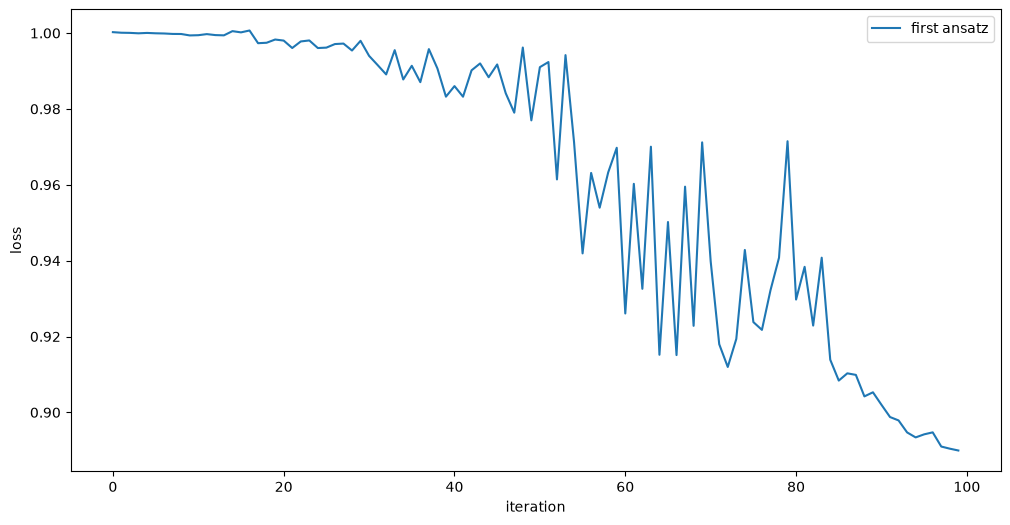

In [20]:
obj_func_vals_first = objective_func_vals
# import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(obj_func_vals_first, label="first ansatz")
plt.xlabel("iteration")
plt.ylabel("loss")
plt.legend()
plt.show()

最適化器がパラメーター空間内の局所的最小値にはまっただけではないことを確かめるために、最適化ステップを増やしてみることも考えられます。しかし、かなり収束しているように見えます。正しく分類 *されなかった* 画像を詳しく見て、何が起きているのかを理解できるか確かめてみましょう。



In [21]:
missed = []
for i in range(len(test_labels)):
    if pred_test_labels[i] != test_labels[i]:
        missed.append(test_images[i])
print(len(missed))

24


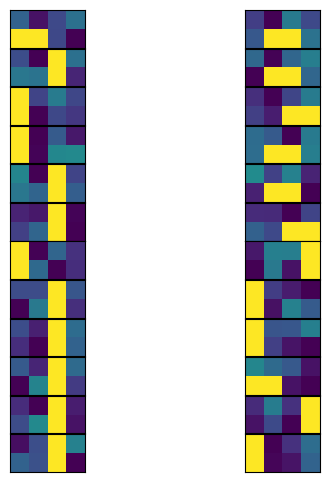

In [22]:
fig, ax = plt.subplots(12, 2, figsize=(6, 6), subplot_kw={"xticks": [], "yticks": []})
for i in range(len(missed)):
    ax[i // 2, i % 2].imshow(
        missed[i].reshape(vert_size, hor_size),
        aspect="equal",
    )
plt.subplots_adjust(wspace=0.02, hspace=0.025)

誤って分類された画像の大部分は垂直線を持つものであることがわかります。モデルの何かが、それらの画像に関する情報を捉えられていません。最初の変分回路から、このことを予想していた方もいるかもしれません。詳しく見てみましょう。

## モデルの改善

### ステップ 1 の再検討

問題を量子回路にマッピングする際、隣接するピクセルの情報がどのようにクラスを決定するのかを明示的に考えるべきでした。水平線を識別するためには、各行のすべてのピクセルについて「ピクセル $i$ が黄色なら、ピクセル $i+1$ も黄色か」を知りたいところです。垂直線についても知りたいところです。しかし、分類は二値なので、そのような水平線が検出 *されなければ* 垂直線である、と単純に言うことも考えられます。以前の変分回路には、量子ビット (したがってピクセル) 0 と 1、1 と 2、2 と 3 の間に CNOT ゲートが含まれていました。これは画像の上部を横切る水平線はカバーしますが、垂直線を直接検出するものではなく、下の行を無視しているため水平線を完全に検出するものでもありません。すべての水平線を完全に検出するには、量子ビット (ピクセル) 4 と 5、5 と 6、6 と 7 の間にも同様の CNOT ゲートの組が必要です。垂直線に対応する量子ビットの間 (0 と 4、2 と 6 など) に CNOT ゲートを追加することも有用かもしれないことは念頭に置いておきましょう。しかしまずは、水平線が *ある* か *ない* かを検出するだけで十分かどうかを確認します。



5
2+ qubit depth: 3


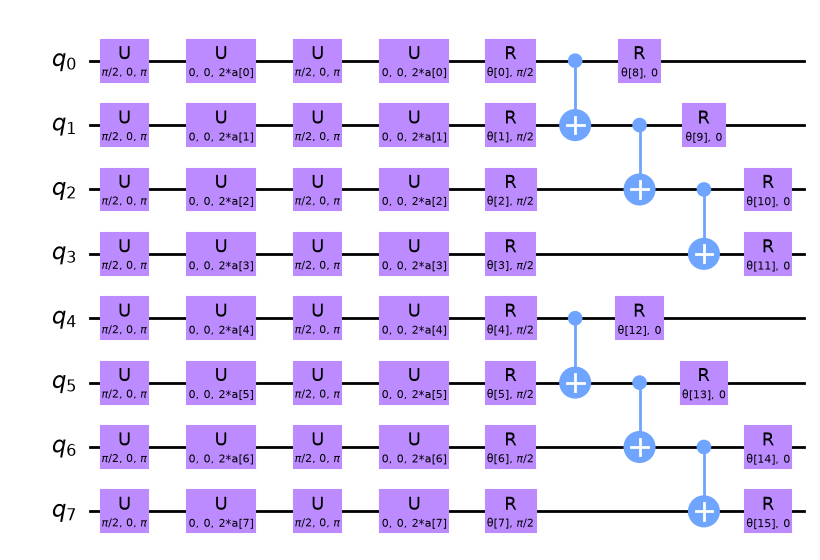

In [23]:
# 画像のピクセル数と同じ数の量子ビットで回路を初期化
qnn_circuit = QuantumCircuit(size)

# 各量子ビットに 2 つの変分パラメーターを持たせることにします。
params = ParameterVector("θ", length=2 * size)

# 1 つ目の変分層:
for i in range(size):
    qnn_circuit.ry(params[i], i)

# CNOT ゲートを配置したい量子ビットのペアを拡張したリストです。これで水平な線でつながる
# すべてのピクセルをカバーします。
qnn_cnot_list = [[0, 1], [1, 2], [2, 3], [4, 5], [5, 6], [6, 7]]

for i in range(len(qnn_cnot_list)):
    qnn_circuit.cx(qnn_cnot_list[i][0], qnn_cnot_list[i][1])

# 2 つ目の変分層:
for i in range(size):
    qnn_circuit.rx(params[size + i], i)

# 回路の深さと 2 量子ビットゲートの深さを確認
print(qnn_circuit.decompose().depth())
print(
    f"2+ qubit depth: {qnn_circuit.decompose().depth(lambda instr: len(instr.qubits) > 1)}"
)

# 特徴量マップと変分回路を結合
ansatz = qnn_circuit

# 特徴量マップとアンザッツを結合
full_circuit = QuantumCircuit(num_qubits)
full_circuit.compose(feature_map, range(num_qubits), inplace=True)
full_circuit.compose(ansatz, range(num_qubits), inplace=True)

# 回路を表示
full_circuit.decompose().draw("mpl", style="clifford", fold=-1)

回路の深さは増えていません。画像をモデル化する能力が向上したかどうかを見てみましょう。

### ステップ 2 の再検討

この新しい回路を実際の量子バックエンドで実行するには、トランスパイルする必要があります。変分回路の修正がシミュレーター上で期待どおりの効果をもたらしたかを確認するため、ここではこのステップをいったん省略します。トランスパイルについては、次のサブセクションでより深く掘り下げます。

### ステップ 3 の再検討

更新したモデルを訓練データに適用します。



In [24]:
from qiskit.primitives import StatevectorEstimator as Estimator

batch_size = 140
num_epochs = 1
num_samples = len(train_images)

# グローバル変数
circuit = full_circuit
estimator = Estimator()  # デバッグ用のシミュレーター
observables = observable
objective_func_vals = []
iter = 0

# アンザッツのランダムな初期重み
np.random.seed(42)
weight_params = np.random.rand(len(ansatz.parameters)) * 2 * np.pi

for epoch in range(num_epochs):
    for i in range((num_samples - 1) // batch_size + 1):
        print(f"Epoch: {epoch}, batch: {i}")
        start_i = i * batch_size
        end_i = start_i + batch_size
        train_images_batch = np.array(train_images[start_i:end_i])
        train_labels_batch = np.array(train_labels[start_i:end_i])
        input_params = train_images_batch
        target = train_labels_batch
        iter = 0
        res = minimize(
            mse_loss_weights, weight_params, method="COBYLA", options={"maxiter": 100}
        )
        weight_params = res["x"]

Epoch: 0, batch: 0
Iter: 0, loss: 1.0049762969140237
Iter: 50, loss: 0.9610166111578137


### ステップ 4 の再検討

まず、最適化器が完全に収束したかどうかを確認しましょう。



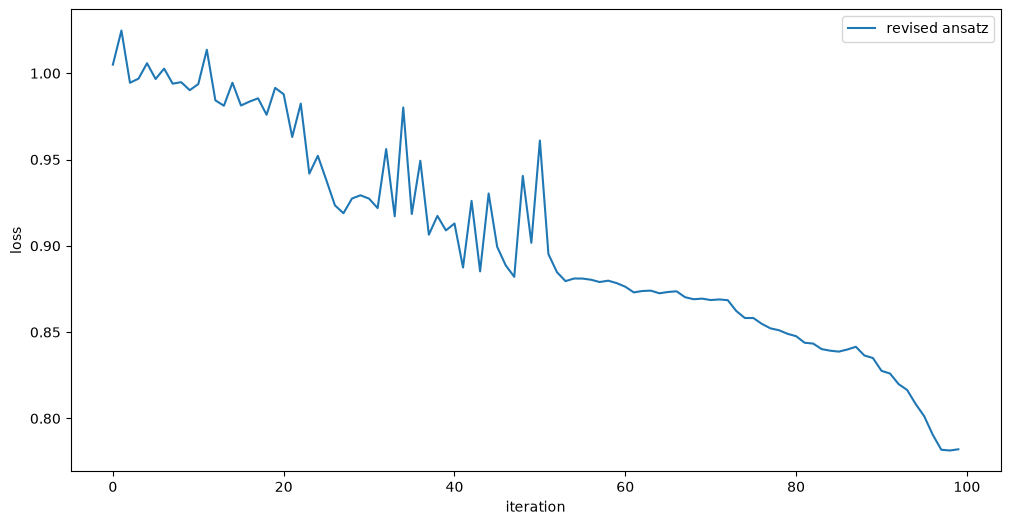

In [25]:
obj_func_vals_revised = objective_func_vals
# import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(obj_func_vals_revised, label="revised ansatz")
plt.xlabel("iteration")
plt.ylabel("loss")
plt.legend()
plt.show()

損失関数が十分に多くのステップにわたってほぼ横ばいになっていないため、完全には収束していないように見えます。しかし、損失関数はすでに以前の変分回路を使った場合よりも \~60% 低くなっています。これが研究プロジェクトであれば、完全な収束を確保したいところです。しかし、探求が目的であれば、これで十分です。訓練データとテストデータに対する精度を確認しましょう。



In [26]:
from sklearn.metrics import accuracy_score
from qiskit.primitives import StatevectorEstimator as Estimator  # シミュレーター
# from qiskit_ibm_runtime import EstimatorV2 as Estimator  # 実際の量子コンピューター

estimator = Estimator()
# estimator = Estimator(backend=backend)

pred_train = forward(circuit, np.array(train_images), res["x"], estimator, observable)
# pred_train = forward(circuit_ibm, np.array(train_images), res['x'], estimator, observable_ibm)

print(pred_train)

pred_train_labels = copy.deepcopy(pred_train)
pred_train_labels[pred_train_labels >= 0] = 1
pred_train_labels[pred_train_labels < 0] = -1
print(pred_train_labels)
print(train_labels)

accuracy = accuracy_score(train_labels, pred_train_labels)
print(f"Train accuracy: {accuracy * 100}%")

[ 0.17588365  0.06358946  0.03154715  0.40568015 -0.26663654  0.35052378
  0.32532118  0.42179424 -0.12503935  0.01735073  0.34210006  0.03982966
  0.22643087 -0.4412831  -0.08404207 -0.21145139 -0.0864077  -0.08422211
  0.1610014   0.16197725  0.40828044 -0.14028519  0.12610441  0.33568985
 -0.21658925  0.14599275  0.2047188   0.27508696  0.38082561 -0.07229336
  0.01794865  0.29048418 -0.10297829  0.12442964  0.38024615  0.17366051
  0.06349612  0.27704119 -0.13239334 -0.02905743  0.03690951  0.18908208
  0.31179867 -0.45557033  0.0577176  -0.10626097  0.28010561  0.23700008
 -0.16567916  0.15686607  0.12601319  0.23702745  0.12737872 -0.14154204
  0.13267215  0.39800623  0.03006156  0.46442971 -0.21106578 -0.34238585
 -0.10174681  0.21789043  0.08702818 -0.1833671   0.32475031  0.2210001
  0.38867033 -0.10543421  0.09170983  0.45790369  0.09308404  0.2297307
  0.38493105  0.3522148  -0.03609128  0.0977109   0.20883459  0.07064556
  0.18794959  0.16861158  0.30113559  0.45925807  0.4

In [27]:
pred_test = forward(circuit, np.array(test_images), res["x"], estimator, observable)
# pred_test = forward(circuit_ibm, np.array(test_images), res['x'], estimator, observable_ibm)

print(pred_test)

pred_test_labels = copy.deepcopy(pred_test)
pred_test_labels[pred_test_labels >= 0] = 1
pred_test_labels[pred_test_labels < 0] = -1
print(pred_test_labels)
print(test_labels)

accuracy = accuracy_score(test_labels, pred_test_labels)
print(f"Test accuracy: {accuracy * 100}%")

[ 0.15991126 -0.38271809  0.16161486  0.04462364 -0.22646557 -0.0807667
  0.47175973  0.00123989  0.09548693 -0.29120313  0.02120809  0.2205051
  0.27667248  0.01682459 -0.16974311  0.1939437  -0.36231285  0.1744752
  0.36515602  0.17900844  0.14718311 -0.11755908  0.07757464  0.2714839
  0.01625922 -0.29012097  0.33790635  0.03022243  0.35925687  0.25999274
  0.14048379 -0.25958896  0.08768122  0.33258691  0.06325939  0.31244923
  0.20687033  0.10872432  0.30611549 -0.23099417  0.03384005 -0.18916946
  0.04495479  0.49401586  0.18620635 -0.10690734  0.12783912  0.25469493
  0.26001136  0.22831741  0.1465171   0.08602245  0.19535164  0.02265729
  0.15900032  0.30678305  0.05103284  0.39003678 -0.25936609  0.29612062]
[ 1. -1.  1.  1. -1. -1.  1.  1.  1. -1.  1.  1.  1.  1. -1.  1. -1.  1.
  1.  1.  1. -1.  1.  1.  1. -1.  1.  1.  1.  1.  1. -1.  1.  1.  1.  1.
  1.  1.  1. -1.  1. -1.  1.  1.  1. -1.  1.  1.  1.  1.  1.  1.  1.  1.
  1.  1.  1.  1. -1.  1.]
[-1, -1, 1, 1, -1, -1, 1, -1

両方のセットで $100\%$ の精度です！水平線を正確に検出できれば十分だろうという予想は正しかったのです！さらに、ピクセルについて必要な情報から量子回路内の CNOT ゲートへのマッピングも効果的でした。次に、実際の量子コンピューターで実行する際に、このプロセスがどのようにスケールするかを見ていきましょう。



## スケーリングと実際の量子コンピューターでの実行

### データ

まず、画像のサイズを大きくすることから始めましょう。6x6 のグリッドを選んだことに特別な理由はありませんが、非クリフォードゲートを使う回路でシミュレーションできる量子ビット数 (32) を超えています。



In [28]:
# このコードは分類対象の画像を定義します:

import numpy as np

# 「ピクセル」/量子ビットの総数
size = 36
# 画像の一方の次元 (縦と呼びますが、どちらでも構いません)。`size` の約数である必要があります
vert_size = 6
# 検出する線 (黄色) の長さ。画像の最小の次元以下である必要があります
# (`<=min(vert_size,size/vert_size)`
line_size = 6


def generate_dataset(num_images):
    images = []
    labels = []
    hor_array = np.zeros((size - (line_size - 1) * vert_size, size))
    ver_array = np.zeros((round(size / vert_size) * (vert_size - line_size + 1), size))

    j = 0
    for i in range(0, size - 1):
        if i % (size / vert_size) <= (size / vert_size) - line_size:
            for p in range(0, line_size):
                hor_array[j][i + p] = np.pi / 2
            j += 1

    # 隣接する 2 つの要素を pi/2 にし、次の行へ移ります。このリストをグリッドに折りたたむため、
    # size/vert_size - linesize にある「ピクセル」を避けるよう注意します。

    j = 0
    for i in range(0, round(size / vert_size) * (vert_size - line_size + 1)):
        for p in range(0, line_size):
            ver_array[j][i + p * round(size / vert_size)] = np.pi / 2
        j += 1

    # 長さ/行数の間隔で要素を pi/2 にします。こうすると折りたたんだときに、
    # それらの要素が上下に並びます。

    for n in range(num_images):
        rng = np.random.randint(0, 2)
        if rng == 0:
            labels.append(-1)
            random_image = np.random.randint(0, len(hor_array))
            images.append(np.array(hor_array[random_image]))
            # 上で作成した複数の行のうち 1 つをランダムに選択します。
        elif rng == 1:
            labels.append(1)
            random_image = np.random.randint(0, len(ver_array))
            images.append(np.array(ver_array[random_image]))
            # 上で作成した複数の行のうち 1 つをランダムに選択します。

        # ノイズを生成
        for i in range(size):
            if images[-1][i] == 0:
                images[-1][i] = np.random.rand() * np.pi / 4
    return images, labels


hor_size = round(size / vert_size)

量子コンピューティングの時間は貴重なリソースなので、非常に小さな訓練セットとごく少数の最適化ステップを使用します。ワークフローを示すにはこれで十分です。



In [29]:
from sklearn.model_selection import train_test_split

np.random.seed(42)
# ここでは非常に小さなデータセットを指定します。より現実的にするには増やしてください。ただし、
# 量子コンピューティング時間の使用量に注意してください。
images, labels = generate_dataset(10)

train_images, test_images, train_labels, test_labels = train_test_split(
    images, labels, test_size=0.3, random_state=246
)

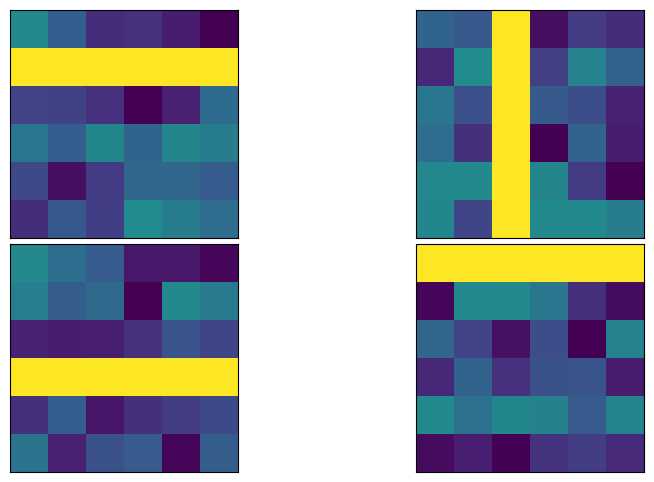

In [30]:
import matplotlib.pyplot as plt

# サブプロットを使って画像を並べた図を生成します。

fig, ax = plt.subplots(2, 2, figsize=(10, 6), subplot_kw={"xticks": [], "yticks": []})
for i in range(4):
    ax[i // 2, i % 2].imshow(
        train_images[i].reshape(vert_size, hor_size),
        aspect="equal",
    )
plt.subplots_adjust(wspace=0.1, hspace=0.025)

### ステップ 1: 問題を量子回路にマッピングする



In [31]:
from qiskit.circuit.library import z_feature_map

# データの特徴量 1 つにつき 1 量子ビット
num_qubits = len(train_images[0])

# データのエンコーディング
# Qiskit はパラメーターをアルファベット順に並べることに注意してください。データのエンコーディングが
# 回路の最初の部分 (特徴量マップ) に確実に入るよう、パラメーターの接頭辞として "a" を割り当てます。
feature_map = z_feature_map(num_qubits, parameter_prefix="a")

In [32]:
# cx を圧縮した順序で配置した回路を作成します。

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector

qnn_circuit = QuantumCircuit(size)
params = ParameterVector("θ", length=2 * size)
for i in range(size):
    qnn_circuit.ry(params[i], i)

# 水平方向に隣接する量子ビット間の CNOT ゲート。
for i in range(vert_size):
    for j in range(hor_size):
        if j < hor_size - 1:
            qnn_circuit.cx((i * hor_size) + j, (i * hor_size) + j + 1)

# 垂直方向に隣接する量子ビット間の CNOT ゲート。予備的なシミュレーションの結果から、
# おそらく不要です。

#        if i<vert_size-1:
#            qnn_circuit.cx((i*hor_size)+j,(i*hor_size)+j+hor_size)
for i in range(size):
    qnn_circuit.rx(params[size + i], i)
qnn_circuit_large = qnn_circuit

print(qnn_circuit_large.decompose().depth())
print(
    f"2+ qubit depth: {qnn_circuit_large.decompose().depth(lambda instr: len(instr.qubits) > 1)}"
)
# qnn_circuit_large.draw()

7
2+ qubit depth: 5


これは妥当な 2 量子ビットの深さです。実際の量子コンピューターから高品質な結果が得られるはずです。



In [33]:
# 特徴量マップと変分回路を結合
ansatz = qnn_circuit

# 特徴量マップとアンザッツを結合
full_circuit = QuantumCircuit(num_qubits)
full_circuit.compose(feature_map, range(num_qubits), inplace=True)
full_circuit.compose(ansatz, range(num_qubits), inplace=True)

# 回路全体の深さを確認
print(full_circuit.decompose().depth())
print(
    f"2+ qubit depth: {full_circuit.decompose().depth(lambda instr: len(instr.qubits) > 1)}"
)

11
2+ qubit depth: 5


CNOT ゲートを持たない `z_feature_map` を使用しているため、エンコーディング層を追加しても 2 量子ビットの深さは増えません。ここで回路全体を可視化できます。



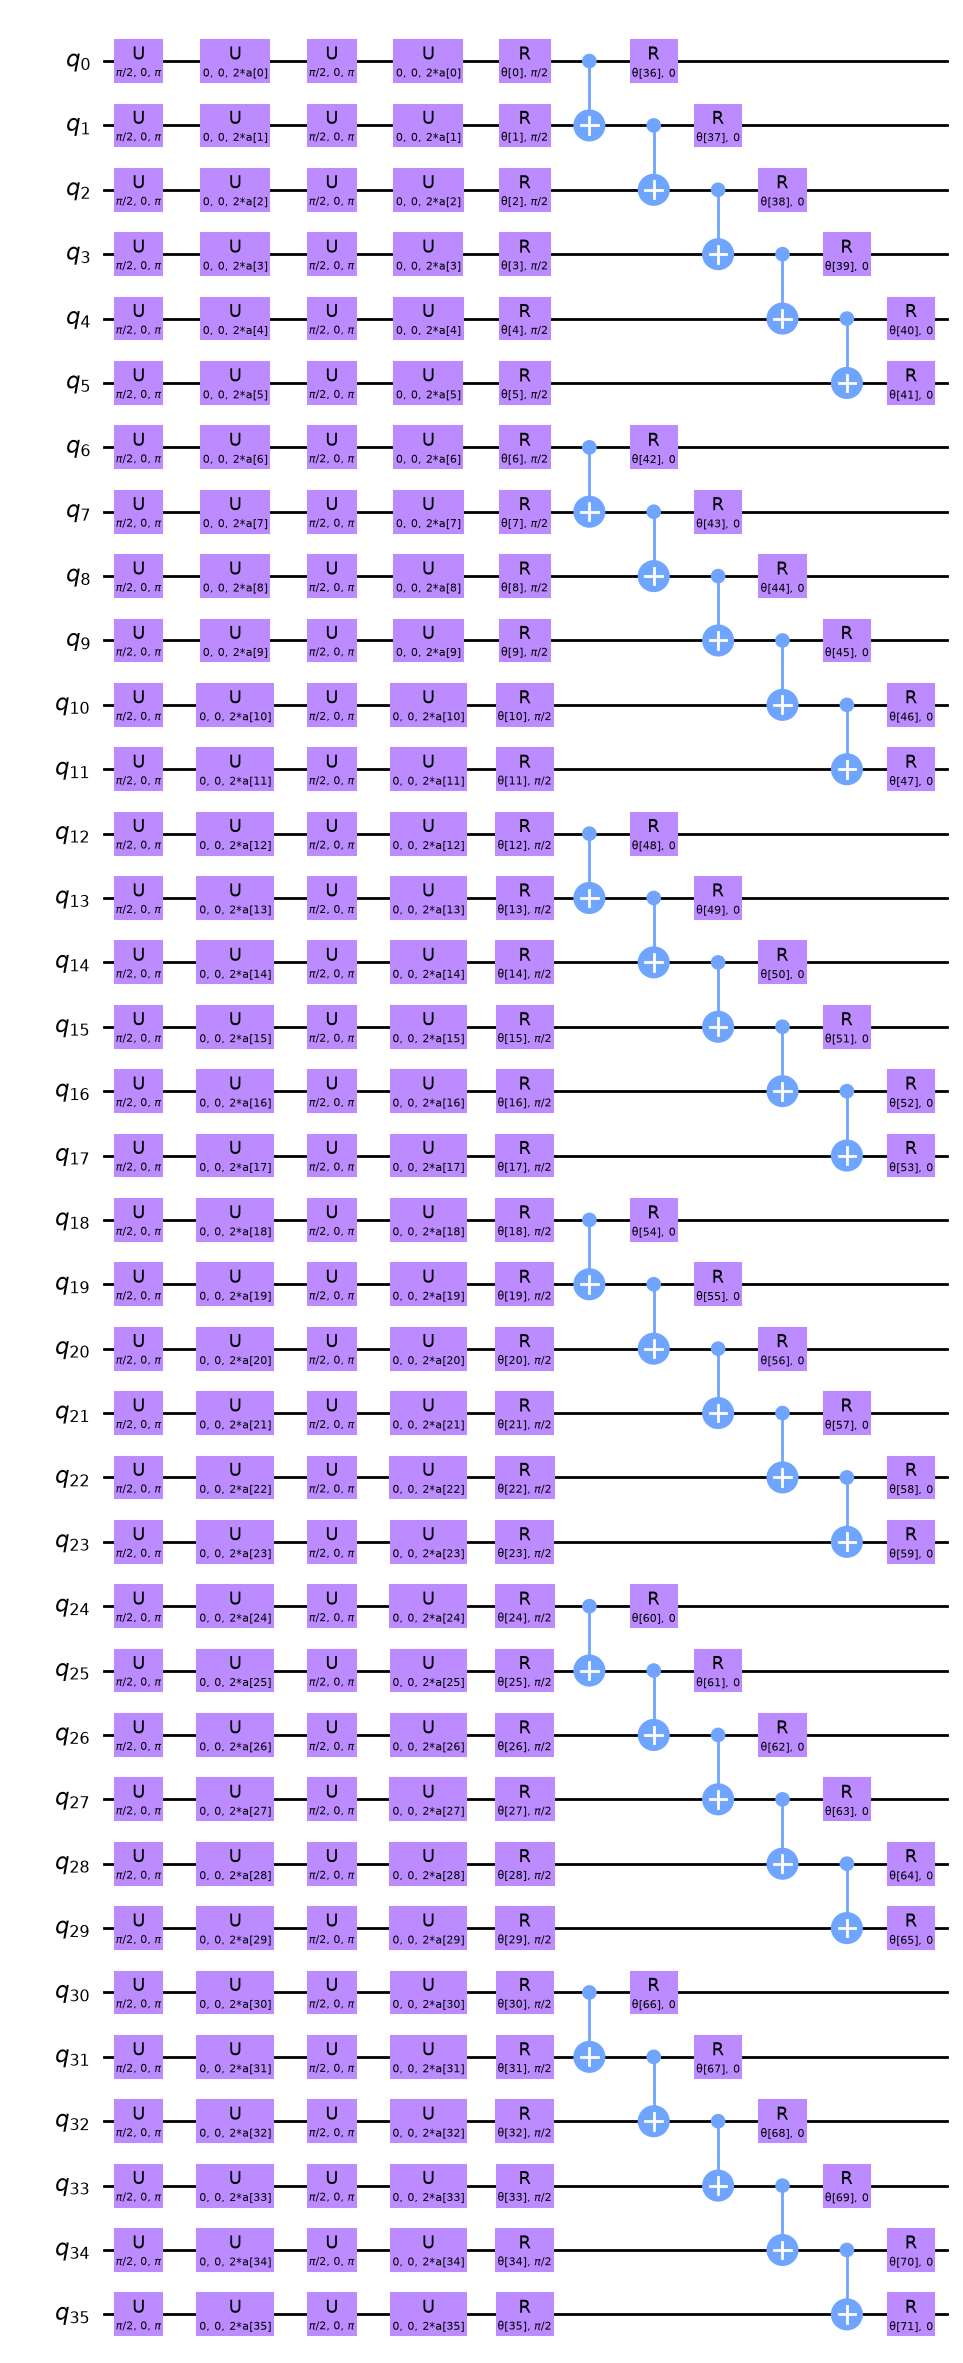

In [34]:
full_circuit.decompose().draw("mpl", style="clifford", idle_wires=False, fold=-1)

2 量子ビットの深さを最小化することが最も重要であれば、CNOT の順序を変更することで実際に深さを少し減らせることに気付いたかもしれません。たとえば、上の回路図で $q_{35}$ と $q_{34}$ の CNOT を左に移動させ、たとえば $q_{30}$ と $q_{31}$ の CNOT の真下に配置することができます。2 量子ビットゲートの深さが 5 の場合、トランスパイル後にこれで違いが出るかは明らかではありませんが、念頭に置いておくべきことです。CNOT ゲートの順序が目の前の問題と論理的に対応させるうえで重要であれば、ここでの深さで問題ありません。CNOT の順序が画像のデータ構造をモデル化するうえで重要でなければ、深さを最小化するようにこれらの CNOT ゲートを並べ替えるスクリプトを書くこともできます。

また、より大きな画像に合わせてオブザーバブルを再定義する必要もあります。



In [35]:
from qiskit.quantum_info import SparsePauliOp

observable = SparsePauliOp.from_list([("Z" * (num_qubits), 1)])

## Qiskit Patterns ステップ 2: 量子実行のために問題を最適化する

まず、実行するバックエンドを選択します。ここでは、最も空いているバックエンドを使用します。



In [36]:
from qiskit_ibm_runtime import QiskitRuntimeService

# ハードウェアで実行するには、最も空いている量子コンピューターを選択するか、特定のものを指定します。
service = QiskitRuntimeService()
backend = service.least_busy(operational=True, simulator=False)
# backend = service.backend("ibm_brisbaneane")

print(backend.name)

ibm_fez


ここでも、最適化レベルを 3 に設定したパスマネージャーを定義します。



In [37]:
from qiskit.circuit.library import XGate
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import (
    ALAPScheduleAnalysis,
    ConstrainedReschedule,
    PadDynamicalDecoupling,
)
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target

pm = generate_preset_pass_manager(target=target, optimization_level=3)
pm.scheduling = PassManager(
    [
        ALAPScheduleAnalysis(target=target),
        ConstrainedReschedule(
            acquire_alignment=target.acquire_alignment,
            pulse_alignment=target.pulse_alignment,
            target=target,
        ),
        PadDynamicalDecoupling(
            target=target,
            dd_sequence=[XGate(), XGate()],
            pulse_alignment=target.pulse_alignment,
        ),
    ]
)

次に、パスマネージャーを何度か適用します。非常に幅の広い回路や非常に深い回路では、トランスパイル後の 2 量子ビットの深さに大きなばらつきが生じることがあります。そのような回路では、パスマネージャーを何度も試して、最良の (最も浅い) 結果を使用することが重要です。



In [ ]:
# 大規模な回路ではヒューリスティクスによってさまざまなトランスパイル結果が得られる可能性があり、
# 最も浅いものを使いたいので、パスマネージャーを何度か試します。

transpiled_qcs = []
transpiled_depths = []
transpiled_2q_depths = []
for i in range(1, 10):
    circuit_ibm = pm.run(full_circuit)
    transpiled_qcs.append(circuit_ibm)
    transpiled_depths.append(circuit_ibm.decompose().depth())
    transpiled_2q_depths.append(
        circuit_ibm.decompose().depth(lambda instr: len(instr.qubits) > 1)
    )
    # print(i)

print(transpiled_depths)
print(transpiled_2q_depths)

# 最も浅いものを使用

minpos = transpiled_2q_depths.index(min(transpiled_2q_depths))

この場合、トランスパイル後の 2 量子ビットの深さは常に 10 であったことがわかります。1 量子ビットの深さにはわずかなばらつきがあったので、最も浅いものを使用します。ただし、この 36 量子ビットの回路では、これは決定的な改善ではありません。このトランスパイル後の回路を可視化することもできますが、この規模になると目で見て読み解くのはますます難しくなります。



In [76]:
circuit_ibm = transpiled_qcs[2]
observable_ibm = observable.apply_layout(circuit_ibm.layout)
print(circuit_ibm.decompose().depth())
print(
    f"2+ qubit depth: {circuit_ibm.decompose().depth(lambda instr: len(instr.qubits) > 1)}"
)

81
2+ qubit depth: 10


## Qiskit Patterns ステップ 3: IBM Quantum のプリミティブを使って実行する

実際の量子コンピューターの使用時間を抑えるため、ここではごく少数の最適化ステップのみを、非常に小さな訓練セットに対して実行します。しかし、これをより多くの最適化ステップやより大きなテストデータセットにスケールさせる方法は、レッスン全体の説明から明らかでしょう。



In [ ]:
# これは 2024 年 10 月 4 日に Eagle r3 プロセッサーで実行され、7 分かかりました。

from qiskit_ibm_runtime import EstimatorV2 as Estimator, Session

batch_size = 7
num_epochs = 1
num_samples = len(train_images)

# グローバル変数
circuit = circuit_ibm
observable = observable_ibm
objective_func_vals = []
iter = 0

# アンザッツのランダムな初期重み
np.random.seed(42)
# weight_params = np.random.rand(len(ansatz.parameters)) * 2 * np.pi
# または、以前の計算で得た重みを再読み込み
weight_params = np.array(
    [
        3.35330497,
        5.97351416,
        4.59925358,
        3.76148219,
        0.98029403,
        0.98014248,
        0.3649501,
        6.44234523,
        3.77691701,
        4.44895122,
        0.12933619,
        6.09412333,
        5.23039137,
        1.33416598,
        1.14243996,
        1.15236452,
        1.91161039,
        3.2971419,
        3.71399059,
        1.82984665,
        3.84438512,
        0.87646578,
        1.83559896,
        2.30191935,
        2.86557222,
        4.93340606,
        1.25458737,
        3.23103027,
        3.72225051,
        0.29185655,
        3.81731689,
        1.07143467,
        0.40873121,
        5.96202367,
        6.067245,
        5.07931034,
        1.91394476,
        0.61369199,
        4.2991629,
        2.76555968,
        0.76678884,
        3.11128829,
        0.21606945,
        5.71342859,
        1.62596258,
        4.16275028,
        1.95853845,
        3.26768375,
        3.43508199,
        1.1614748,
        6.09207989,
        4.87030317,
        5.90304595,
        5.62236606,
        3.75671636,
        5.79230665,
        0.55601479,
        1.23139664,
        0.28417144,
        2.04411075,
        2.44213144,
        1.70493625,
        5.20711134,
        2.24154726,
        1.76516358,
        3.40986006,
        0.88545302,
        5.04035228,
        0.46841551,
        6.2007935,
        4.85215699,
        1.24856745,
    ]
)

# セッションで実行すると、繰り返しキューに入るのを避けられます。これは Premium Plan、Flex Plan、
# On-Prem (IBM Quantum Platform API) Plan のユーザーが利用できます。

with Session(backend=backend) as session:
    estimator = Estimator(mode=session, options={"resilience_level": 1})

    for epoch in range(num_epochs):
        for i in range((num_samples - 1) // batch_size + 1):
            print(f"Epoch: {epoch}, batch: {i}")
            start_i = i * batch_size
            end_i = start_i + batch_size
            train_images_batch = np.array(train_images[start_i:end_i])
            train_labels_batch = np.array(train_labels[start_i:end_i])
            input_params = train_images_batch
            target = train_labels_batch
            iter = 0
            # maxiter を増やせば完全な最適化を行えます。
            res = minimize(
                mse_loss_weights,
                weight_params,
                method="COBYLA",
                options={"maxiter": 20},
            )
            weight_params = res["x"]
session.close()

# Open Plan のユーザーはバッチを使って同じ計算を行えますが、繰り返しキューに入る可能性があります。
# from qiskit_ibm_runtime import Batch

# with Batch(backend=backend) as batch:
#    estimator = Estimator(
#        mode=batch, options={"resilience_level": 1}
#    )
#
#    for epoch in range(num_epochs):
#        for i in range((num_samples - 1) // batch_size + 1):
#            print(f"Epoch: {epoch}, batch: {i}")
#            start_i = i * batch_size
#            end_i = start_i + batch_size
#            train_images_batch = np.array(train_images[start_i:end_i])
#            train_labels_batch = np.array(train_labels[start_i:end_i])
#            input_params = train_images_batch
#            target = train_labels_batch
#            iter = 0
#            # maxiter を増やせば完全な最適化を行えます。
#            res = minimize(
#                mse_loss_weights,
#                weight_params,
#                method="COBYLA",
#                options={"maxiter": 20},
#            )
#            weight_params = res["x"]
# batch.close()

さらに反復を行う場合に備えて、この計算で返された重みパラメーターを保存しておくことをお勧めします。



In [85]:
weight_params

array([3.35330497, 6.97351416, 5.59925358, 3.76148219, 0.98029403,
       0.98014248, 0.3649501 , 6.44234523, 3.77691701, 4.44895122,
       1.12933619, 7.09412333, 5.23039137, 1.33416598, 1.14243996,
       1.15236452, 1.91161039, 3.2971419 , 3.71399059, 1.82984665,
       3.84438512, 0.87646578, 1.83559896, 2.30191935, 2.86557222,
       4.93340606, 1.25458737, 3.23103027, 3.72225051, 0.29185655,
       3.81731689, 1.07143467, 0.40873121, 5.96202367, 6.067245  ,
       5.07931034, 1.91394476, 0.61369199, 4.2991629 , 2.76555968,
       0.76678884, 3.11128829, 0.21606945, 5.71342859, 1.62596258,
       4.16275028, 1.95853845, 3.26768375, 3.43508199, 1.1614748 ,
       6.09207989, 4.87030317, 5.90304595, 5.62236606, 3.75671636,
       5.79230665, 0.55601479, 1.23139664, 0.28417144, 2.04411075,
       2.44213144, 1.70493625, 5.20711134, 2.24154726, 1.76516358,
       3.40986006, 0.88545302, 5.04035228, 0.46841551, 6.2007935 ,
       4.85215699, 1.24856745])

最初のいくつかの最適化ステップをプロットできますが、わずか数ステップの最適化で収束が見られるとは期待できません。これらの曲線は、シミュレーターを使った場合でも、最初の数ステップでは比較的平坦でした。ただし、現在の最適化には 72 個の自由パラメーターがあることに注意すべきです。たとえば、行と列全体の一部に対応するデータで量子ビットをパラメーター化することで、結果を損なうことなく、これを少なくとも 2〜3 分の 1 に減らすことができます。実際、損失関数の最小化にさらに量子コンピューティングの時間を費やす前に、パラメーター空間を縮小すべきです。



In [ ]:
obj_func_vals_qc = objective_func_vals
# import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(obj_func_vals_qc, label="revised ansatz")
plt.xlabel("iteration")
plt.ylabel("loss")
plt.legend()
plt.show()

<Image src="/learning/images/courses/quantum-machine-learning/qvc-qnn/extracted-outputs/d8244ff1-a7c5-46e1-87b1-e20b506ef4d8-0.avif" alt="Output of the previous code cell" />

### まとめ

このレッスンでは、量子ニューラルネットワークを使った画像の二値分類のワークフローを学びました。各 Qiskit patterns ステップにおける主な考慮事項は次のとおりです。

**ステップ 1:** 問題を量子回路にマッピングする

* 訓練データを読み込みます。これは「手作業」で行うことも、`z_feature_map` のような既製の特徴量マップを使って行うこともできます。
* 問題に適した回転層とエンタングルメント層を含むアンザッツを構築します。
* 量子コンピューターで質の高い結果を得るために、回路の深さを監視します。

**ステップ 2:** 量子実行のために問題を最適化する

* バックエンドを選択します。多くの場合、最も空いているものを選びます。
* パスマネージャーを使用して、回路とオブザーバブルの両方を、選択したバックエンドのアーキテクチャーに合わせてトランスパイルします。
* 非常に深い回路や幅の広い回路では、複数回トランスパイルし、最も浅い回路を選択します。

**ステップ 3:** Qiskit (Runtime) のプリミティブを使って実行する

* シミュレーターで予備的な試行を行い、アンザッツをデバッグして最適化します。
* IBM® の量子コンピューターで実行します。

**ステップ 4:** 後処理を行い、古典的な形式で結果を返す

* 訓練データとテストデータに対するモデルの精度を計算します。
* 古典的な最適化の収束を監視します。



## 参考文献

\[1] [https://arxiv.org/abs/2405.00781](https://arxiv.org/abs/2405.00781)



© IBM Corp., 2017-2026